<a href="https://colab.research.google.com/github/rifaa05/Project-Akhir_ML_5C_Kelompok-2/blob/main/Project_ML_Kelompok2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pemeriksaan Dataset Untuk Isian Proposal Heart Failure Prediction

In [5]:
import pandas as pd
from google.colab import files


In [6]:
uploaded = files.upload()
nama_file = list(uploaded.keys())[0]

Saving heart.csv.xls to heart.csv.xls


In [7]:
df = pd.read_csv(nama_file)


In [8]:
print("\n========== DESKRIPSI DATASET ==========")

print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])
print("Kolom target: HeartDisease")
print("Jumlah missing value:", df.isnull().sum().sum())
print("Jumlah baris duplikat:", df.duplicated().sum())


========== DESKRIPSI DATASET ==========
Jumlah baris: 918
Jumlah kolom: 12
Kolom target: HeartDisease
Jumlah missing value: 0
Jumlah baris duplikat: 0


In [9]:
print("\n========== DESKRIPSI KOLOM ==========")

deskripsi = pd.DataFrame({
    "Nama Kolom": df.columns,
    "Tipe Data": df.dtypes.astype(str).values,
    "Jumlah Data Unik": df.nunique().values,
    "Contoh Nilai": [
        str(df[k].dropna().unique()[:5])
        for k in df.columns
    ]
})

print(deskripsi.to_string(index=False))


========== DESKRIPSI KOLOM ==========
    Nama Kolom Tipe Data  Jumlah Data Unik             Contoh Nilai
           Age     int64                50         [40 49 37 48 54]
           Sex    object                 2                ['M' 'F']
 ChestPainType    object                 4 ['ATA' 'NAP' 'ASY' 'TA']
     RestingBP     int64                67    [140 160 130 138 150]
   Cholesterol     int64               222    [289 180 283 214 195]
     FastingBS     int64                 2                    [0 1]
    RestingECG    object                 3    ['Normal' 'ST' 'LVH']
         MaxHR     int64               119    [172 156  98 108 122]
ExerciseAngina    object                 2                ['N' 'Y']
       Oldpeak   float64                53    [0.  1.  1.5 2.  3. ]
      ST_Slope    object                 3     ['Up' 'Flat' 'Down']
  HeartDisease     int64                 2                    [0 1]


In [10]:
print("\n========== TEMUAN AWAL ==========")

# Distribusi target
print("\nDistribusi HeartDisease:")
print(df["HeartDisease"].value_counts().sort_index())

print("\nPersentase HeartDisease:")
print(
    (df["HeartDisease"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

# Pemeriksaan nilai nol
print("\nJumlah nilai nol:")

for kolom in ["RestingBP", "Cholesterol"]:
    print(kolom, ":", (df[kolom] == 0).sum())

# Statistik deskriptif
print("\nStatistik deskriptif:")

kolom_numerik = [
    "Age", "RestingBP", "Cholesterol",
    "MaxHR", "Oldpeak"
]

print(df[kolom_numerik].describe().round(2))

# Pemeriksaan outlier metode IQR
print("\nPemeriksaan outlier metode IQR:")

for kolom in kolom_numerik:
    q1 = df[kolom].quantile(0.25)
    q3 = df[kolom].quantile(0.75)
    iqr = q3 - q1

    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr

    jumlah = (
        (df[kolom] < batas_bawah) |
        (df[kolom] > batas_atas)
    ).sum()

    print(kolom, ":", jumlah, "outlier")



========== TEMUAN AWAL ==========

Distribusi HeartDisease:
HeartDisease
0    410
1    508
Name: count, dtype: int64

Persentase HeartDisease:
HeartDisease
0    44.66
1    55.34
Name: proportion, dtype: float64

Jumlah nilai nol:
RestingBP : 1
Cholesterol : 172

Statistik deskriptif:
          Age  RestingBP  Cholesterol   MaxHR  Oldpeak
count  918.00     918.00       918.00  918.00   918.00
mean    53.51     132.40       198.80  136.81     0.89
std      9.43      18.51       109.38   25.46     1.07
min     28.00       0.00         0.00   60.00    -2.60
25%     47.00     120.00       173.25  120.00     0.00
50%     54.00     130.00       223.00  138.00     0.60
75%     60.00     140.00       267.00  156.00     1.50
max     77.00     200.00       603.00  202.00     6.20

Pemeriksaan outlier metode IQR:
Age : 0 outlier
RestingBP : 28 outlier
Cholesterol : 183 outlier
MaxHR : 2 outlier
Oldpeak : 16 outlier


# VARIAN DASAR:
KLASIFIKASI MENGGUNAKAN ALGORITMA k-NN


Pada varian dasar ini, dilakukan pengujian klasifikasi penyakit jantung menggunakan algoritma k-Nearest Neighbors (k-NN). Pengujian menggunakan nilai K = 5 sebagai nilai awal untuk menentukan jumlah tetangga terdekat dalam proses klasifikasi.

Sebelum model diterapkan, dataset akan melalui beberapa tahapan, yaitu pemisahan fitur dan target, pembagian data training dan testing, serta preprocessing data. Selanjutnya, model dilatih dan diuji untuk mengetahui performanya berdasarkan nilai Accuracy, Precision, Recall, F1-Score, dan Confusion Matrix.

## Tahap 1. Import library


Tahap pertama adalah mengimpor library yang dibutuhkan dalam proses klasifikasi. Library Pandas digunakan untuk mengelola data, Matplotlib dan Seaborn untuk visualisasi, sedangkan Scikit-learn digunakan untuk membagi dataset, melakukan preprocessing, membangun model k-NN, dan mengevaluasi hasil klasifikasi.

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

## Tahap 2. Menentukan fitur dan target


Pada tahap ini, dataset dipisahkan menjadi dua bagian, yaitu fitur dan target. Fitur merupakan variabel yang digunakan sebagai dasar untuk melakukan prediksi, sedangkan target merupakan variabel yang akan diprediksi oleh model.

Dalam penelitian ini, seluruh kolom selain HeartDisease digunakan sebagai fitur, sementara kolom HeartDisease menjadi target klasifikasi.

In [12]:
X = df.drop("HeartDisease", axis=1)
y = df["HeartDisease"]

print("Jumlah fitur:", X.shape[1])
print("Jumlah target:", y.shape[0])

Jumlah fitur: 11
Jumlah target: 918


## Tahap 3. Membagi data training dan testing


Dataset dibagi menjadi data training dan data testing dengan perbandingan 80:20. Data training sebesar 80% digunakan untuk melatih model, sedangkan data testing sebesar 20% digunakan untuk menguji kemampuan model dalam memprediksi data yang belum pernah dipelajari.

Parameter random_state=42 digunakan agar pembagian data dapat direproduksi. Sementara itu, stratify=y digunakan untuk mempertahankan proporsi kelas target pada data training dan testing.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])

Jumlah data training: 734
Jumlah data testing: 184


## Melakukan preprocessing data


Preprocessing dilakukan untuk menyesuaikan format data sebelum digunakan oleh algoritma k-NN. Hal ini penting karena algoritma k-NN menggunakan perhitungan jarak antar data, sehingga perbedaan skala nilai dapat memengaruhi hasil klasifikasi.

Pada penelitian ini, preprocessing dibedakan menjadi dua jenis:
- StandardScaler: digunakan untuk menstandarkan fitur numerik agar memiliki skala yang sebanding.
- OneHotEncoder: digunakan untuk mengubah fitur kategorikal menjadi representasi numerik yang dapat diproses oleh model.

Proses preprocessing disusun menggunakan ColumnTransformer agar setiap kelompok fitur mendapatkan metode pengolahan yang sesuai.

In [14]:
# Kolom numerik
kolom_numerik = [
    "Age",
    "RestingBP",
    "Cholesterol",
    "FastingBS",
    "MaxHR",
    "Oldpeak"
]

# Kolom kategorikal
kolom_kategorikal = [
    "Sex",
    "ChestPainType",
    "RestingECG",
    "ExerciseAngina",
    "ST_Slope"
]

# Preprocessing data
preprocessor = ColumnTransformer(
    transformers=[
        ("numerik", StandardScaler(), kolom_numerik),
        ("kategori", OneHotEncoder(handle_unknown="ignore"),
         kolom_kategorikal)
    ]
)

## Tahap 5. Membuat model k-NN


Pada tahap ini, model klasifikasi k-Nearest Neighbors (k-NN) dibuat dengan menggunakan nilai K sebesar 5. Algoritma k-NN bekerja dengan menentukan lima tetangga terdekat dari suatu data berdasarkan perhitungan jarak. Kelas yang paling banyak muncul di antara tetangga tersebut akan menjadi hasil prediksi.

Model dibangun menggunakan Pipeline agar proses preprocessing dan klasifikasi dapat dijalankan secara berurutan dalam satu alur.

In [15]:
model_knn = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("klasifikasi", KNeighborsClassifier(n_neighbors=5))
])

## Tahap 6. Melatih model


Setelah model dibuat, proses selanjutnya adalah melatih model menggunakan data training. Pada proses ini, model mempelajari pola hubungan antara fitur-fitur dataset dengan kelas target HeartDisease.

In [16]:
model_knn.fit(X_train, y_train)

print("Model k-NN berhasil dilatih!")

Model k-NN berhasil dilatih!


## Tahap 7. Melakukan prediksi


Model yang telah dilatih kemudian digunakan untuk melakukan prediksi terhadap data testing. Hasil prediksi ini akan dibandingkan dengan nilai target sebenarnya untuk mengetahui kemampuan model dalam mengklasifikasikan data.

In [17]:
y_pred = model_knn.predict(X_test)

print("Hasil prediksi:")
print(y_pred)

Hasil prediksi:
[1 0 1 0 0 0 0 1 0 1 1 0 0 0 0 1 0 1 0 1 0 1 0 0 1 1 0 1 1 0 0 1 0 0 1 1 1
 1 0 1 1 0 1 0 1 1 1 0 1 1 1 0 0 0 1 0 1 0 0 0 0 1 0 1 0 0 1 1 0 0 0 1 1 1
 0 1 1 1 1 1 1 1 1 0 1 0 1 1 0 1 0 1 0 0 1 1 1 1 0 1 1 1 1 0 1 1 1 0 0 1 1
 0 0 1 1 0 1 0 1 1 0 1 0 0 0 1 0 1 1 0 1 0 0 0 1 1 1 0 0 0 1 1 0 1 1 1 0 0
 1 1 1 0 1 0 1 1 0 0 1 1 1 0 0 0 1 0 1 1 0 1 1 0 1 1 1 1 0 0 0 0 1 1 0 1]


## Tahap 8. Evaluasi model


Evaluasi dilakukan untuk mengukur performa model k-NN dalam melakukan klasifikasi. Pengukuran menggunakan empat metrik, yaitu:
- Accuracy: mengukur persentase keseluruhan prediksi yang benar.
- Precision: mengukur ketepatan prediksi pada kelas positif.
- Recall: mengukur kemampuan model dalam menemukan data yang benar-benar termasuk kelas positif.
- F1-Score: mengukur keseimbangan antara precision dan recall.

Dalam dataset ini, kelas positif adalah HeartDisease = 1, yaitu data dengan indikasi penyakit jantung berdasarkan label dataset.

In [18]:
akurasi = accuracy_score(y_test, y_pred)
presisi = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("========== HASIL EVALUASI VARIAN DASAR ==========")
print("Algoritma : k-Nearest Neighbors")
print("Nilai K   : 5")
print("Accuracy  :", round(akurasi, 4))
print("Precision :", round(presisi, 4))
print("Recall    :", round(recall, 4))
print("F1-Score  :", round(f1, 4))

========== HASIL EVALUASI VARIAN DASAR ==========
Algoritma : k-Nearest Neighbors
Nilai K   : 5
Accuracy  : 0.8967
Precision : 0.9109
Recall    : 0.902
F1-Score  : 0.9064


## Tahap 9. Menampilkan confusion matrix



Confusion matrix digunakan untuk melihat perbandingan antara hasil prediksi model dengan kelas sebenarnya. Matriks ini menunjukkan jumlah prediksi benar dan salah pada setiap kelas.

Terdapat empat komponen utama, yaitu:
- True Positive (TP): data positif yang diprediksi positif.
- True Negative (TN): data negatif yang diprediksi negatif.
- False Positive (FP): data negatif yang diprediksi positif.
- False Negative (FN): data positif yang diprediksi negatif.

Visualisasi confusion matrix membantu mengetahui jenis kesalahan yang dilakukan model.

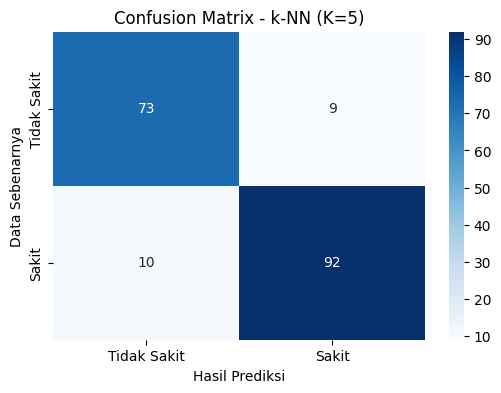

In [19]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Tidak Sakit", "Sakit"],
    yticklabels=["Tidak Sakit", "Sakit"]
)

plt.xlabel("Hasil Prediksi")
plt.ylabel("Data Sebenarnya")
plt.title("Confusion Matrix - k-NN (K=5)")
plt.show()

## Tahap 10. Menampilkan classification report



Classification report digunakan untuk menampilkan hasil evaluasi klasifikasi secara lebih rinci pada setiap kelas. Laporan ini menampilkan precision, recall, f1-score, dan support. Dengan demikian, performa model dapat dilihat secara terpisah untuk kelas HeartDisease = 0 dan HeartDisease = 1.

In [20]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Tidak Sakit", "Sakit"],
    zero_division=0
))

              precision    recall  f1-score   support

 Tidak Sakit       0.88      0.89      0.88        82
       Sakit       0.91      0.90      0.91       102

    accuracy                           0.90       184
   macro avg       0.90      0.90      0.90       184
weighted avg       0.90      0.90      0.90       184



## Tahap 11. Tabel hasil evaluasi

Tahap ini dilakukan untuk merangkum hasil evaluasi model k-NN dengan nilai K = 5 ke dalam bentuk tabel. Tabel berisi nilai Accuracy, Precision, Recall, dan F1-Score yang diperoleh dari pengujian data testing.

In [21]:
# Membuat tabel hasil evaluasi
hasil_evaluasi = pd.DataFrame({
    "Metrik": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],
    "Nilai": [
        round(akurasi, 4),
        round(presisi, 4),
        round(recall, 4),
        round(f1, 4)
    ]
})

# Menampilkan tabel
print("Tabel Hasil Evaluasi Varian Dasar")
display(hasil_evaluasi)

Tabel Hasil Evaluasi Varian Dasar


,Metrik,Nilai
0,Accuracy,0.8967
1,Precision,0.9109
2,Recall,0.9020
3,F1-Score,0.9064


## Hasil Pengujian Varian Dasar


Pengujian varian dasar dilakukan menggunakan algoritma k-Nearest Neighbors (k-NN) dengan nilai K = 5. Berdasarkan proses pengujian yang telah dilakukan, diperoleh hasil evaluasi berupa
- Accuracy sebesar **89,67%**
- Precision sebesar **91,09%**
- Recall sebesar **90,20%**
- F1-Score sebesar **90,64%**.

Berdasarkan hasil tersebut, nilai Accuracy menunjukkan tingkat ketepatan model dalam memprediksi seluruh data pengujian. Nilai Precision menunjukkan ketepatan model ketika memprediksi data ke dalam kelas penyakit jantung. Sementara itu, Recall menunjukkan kemampuan model dalam mengenali data yang termasuk kelas penyakit jantung. F1-Score menggambarkan keseimbangan antara Precision dan Recall.

Selanjutnya, berdasarkan hasil Confusion Matrix, diperoleh:

- **True Positive (TP):** 92
- **True Negative (TN):** 73
- **False Positive (FP):** 9
- **False Negative (FN):** 10

Hasil tersebut menunjukkan bahwa model berhasil memprediksi 92 data dengan label penyakit jantung dan 73 data dengan label tidak sakit secara benar. Sementara itu, terdapat 9 data tidak sakit yang diprediksi sebagai sakit dan 10 data sakit yang diprediksi sebagai tidak sakit.

Secara keseluruhan, pengujian ini memberikan gambaran awal mengenai performa algoritma k-NN dengan nilai K = 5 dalam melakukan klasifikasi pada dataset Heart Failure Prediction.

# **VARIAN 2**

Jumlah data training: 734
Jumlah data testing: 184

CLASSIFICATION REPORT K=3
              precision    recall  f1-score   support

 Tidak Sakit       0.91      0.84      0.87        82
       Sakit       0.88      0.93      0.90       102

    accuracy                           0.89       184
   macro avg       0.89      0.89      0.89       184
weighted avg       0.89      0.89      0.89       184


CLASSIFICATION REPORT K=5
              precision    recall  f1-score   support

 Tidak Sakit       0.88      0.89      0.88        82
       Sakit       0.91      0.90      0.91       102

    accuracy                           0.90       184
   macro avg       0.90      0.90      0.90       184
weighted avg       0.90      0.90      0.90       184


CLASSIFICATION REPORT K=7
              precision    recall  f1-score   support

 Tidak Sakit       0.91      0.89      0.90        82
       Sakit       0.91      0.93      0.92       102

    accuracy                           0.91       

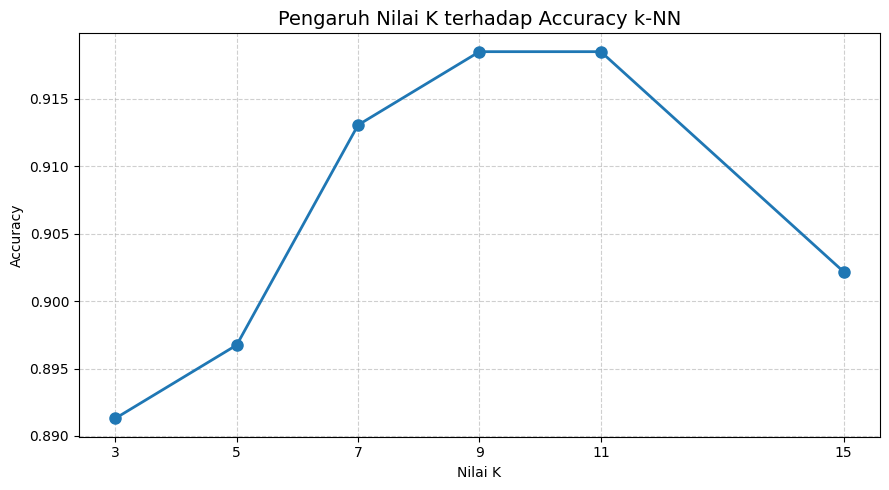

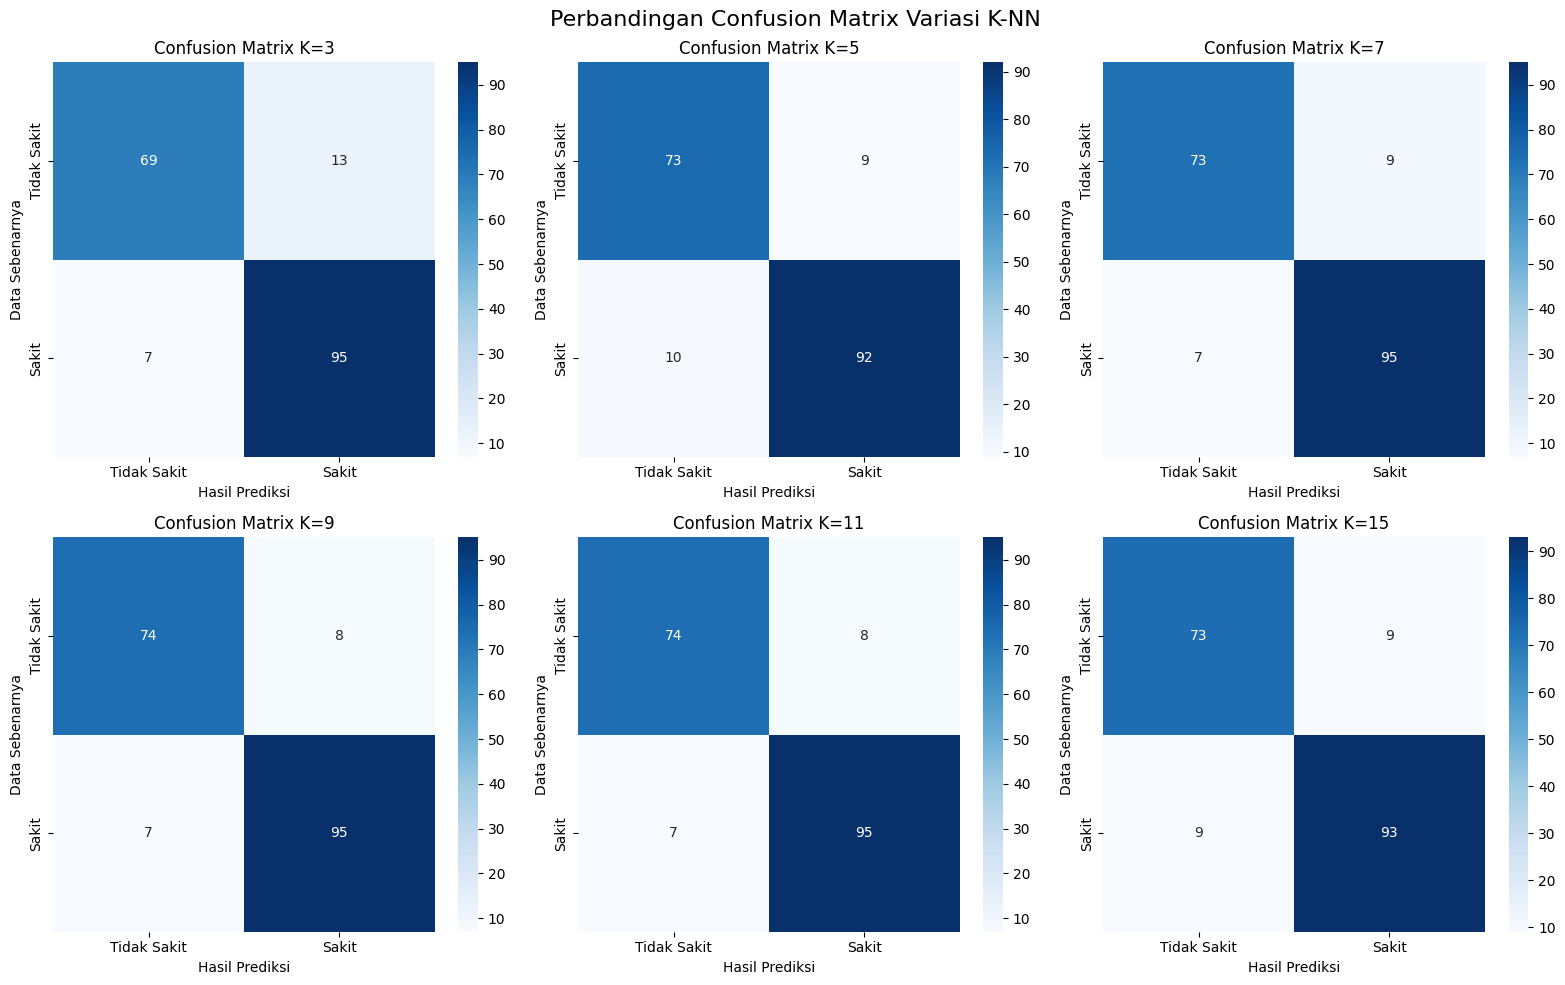


RINGKASAN HASIL EKSPERIMEN K-NN


,Nilai K,Accuracy,Precision,Recall,F1-Score
0,3,89.13%,87.96%,93.14%,90.48%
1,5,89.67%,91.09%,90.20%,90.64%
2,7,91.30%,91.35%,93.14%,92.23%
3,9,91.85%,92.23%,93.14%,92.68%
4,11,91.85%,92.23%,93.14%,92.68%
5,15,90.22%,91.18%,91.18%,91.18%


In [22]:

# =====================================================
# EKSPERIMEN VARIASI PARAMETER K-NN
# HEART FAILURE PREDICTION
# =====================================================

# 1. IMPORT LIBRARY
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


# =====================================================
# 2. MEMISAHKAN FITUR DAN TARGET
# =====================================================

X = df.drop("HeartDisease", axis=1)
y = df["HeartDisease"]


# =====================================================
# 3. MENENTUKAN FITUR NUMERIK DAN KATEGORIK
# =====================================================

numerical_features = [
    "Age",
    "RestingBP",
    "Cholesterol",
    "FastingBS",
    "MaxHR",
    "Oldpeak"
]

categorical_features = [
    "Sex",
    "ChestPainType",
    "RestingECG",
    "ExerciseAngina",
    "ST_Slope"
]


# =====================================================
# 4. PREPROCESSING DATA
# =====================================================

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)


# =====================================================
# 5. MEMBAGI DATA TRAINING DAN TESTING
# =====================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])


# =====================================================
# 6. EKSPERIMEN VARIASI NILAI K
# =====================================================

daftar_k = [3, 5, 7, 9, 11, 15]

hasil_evaluasi = []
confusion_matrices = {}

for k in daftar_k:

    # Membuat pipeline model
    model = Pipeline([
        ("preprocessing", preprocessor),
        ("knn", KNeighborsClassifier(n_neighbors=k))
    ])

    # Melatih model
    model.fit(X_train, y_train)

    # Prediksi data testing
    y_pred = model.predict(X_test)

    # Menghitung metrik evaluasi
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    # Menyimpan hasil evaluasi
    hasil_evaluasi.append({
        "Nilai K": k,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

    # Menyimpan confusion matrix
    confusion_matrices[k] = confusion_matrix(
        y_test, y_pred
    )

    # Menampilkan classification report
    print(f"\nCLASSIFICATION REPORT K={k}")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Tidak Sakit", "Sakit"],
        zero_division=0
    ))


# =====================================================
# 7. MENAMPILKAN TABEL HASIL EVALUASI
# =====================================================

hasil_df = pd.DataFrame(hasil_evaluasi)

print("\n==========================================")
print("TABEL PERBANDINGAN HASIL VARIASI NILAI K")
print("==========================================")

print(hasil_df.round(4).to_string(index=False))


# =====================================================
# 8. MENENTUKAN NILAI K TERBAIK
# =====================================================

nilai_tertinggi = hasil_df["Accuracy"].max()

model_terbaik = hasil_df[
    hasil_df["Accuracy"] == nilai_tertinggi
]

print("\n==========================================")
print("HASIL PARAMETER TERBAIK")
print("==========================================")

print("Accuracy tertinggi:", round(nilai_tertinggi, 4))
print("Nilai K terbaik:", model_terbaik["Nilai K"].tolist())
print("F1-Score:", model_terbaik["F1-Score"].tolist())


# =====================================================
# 9. VISUALISASI GRAFIK ACCURACY
# =====================================================

plt.figure(figsize=(9, 5))

plt.plot(
    hasil_df["Nilai K"],
    hasil_df["Accuracy"],
    marker="o",
    linewidth=2,
    markersize=8
)

plt.title(
    "Pengaruh Nilai K terhadap Accuracy k-NN",
    fontsize=14
)

plt.xlabel("Nilai K")
plt.ylabel("Accuracy")

plt.xticks(daftar_k)
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


# =====================================================
# 10. VISUALISASI SEMUA CONFUSION MATRIX
# =====================================================

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 10)
)

axes = axes.flatten()

for i, k in enumerate(daftar_k):

    cm = confusion_matrices[k]

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Tidak Sakit", "Sakit"],
        yticklabels=["Tidak Sakit", "Sakit"],
        ax=axes[i]
    )

    axes[i].set_title(
        f"Confusion Matrix K={k}"
    )

    axes[i].set_xlabel("Hasil Prediksi")
    axes[i].set_ylabel("Data Sebenarnya")

plt.suptitle(
    "Perbandingan Confusion Matrix Variasi K-NN",
    fontsize=16
)

plt.tight_layout()
plt.show()


# =====================================================
# 11. TABEL RINGKASAN HASIL EKSPERIMEN
# =====================================================

print("\n==========================================")
print("RINGKASAN HASIL EKSPERIMEN K-NN")
print("==========================================")

display(
    hasil_df.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1-Score": "{:.2%}"
    })
)


# **VARIAN 3 — KLASIFIKASI MENGGUNAKAN ALGORITMA NAIVE BAYES**

# Tahap 1 - Import library


In [23]:

# ==========================================
# VARIAN 3: NAIVE BAYES
# HEART FAILURE PREDICTION
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (
    StandardScaler,
    OrdinalEncoder
)

from sklearn.naive_bayes import (
    GaussianNB,
    CategoricalNB
)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


# Tahap 2 - Menentukan fitur dan target

In [24]:

# Memisahkan fitur dan target

X = df.drop("HeartDisease", axis=1)
y = df["HeartDisease"]

print("Jumlah fitur:", X.shape[1])
print("Jumlah target:", y.shape[0])
print("Target klasifikasi: HeartDisease")


Jumlah fitur: 11
Jumlah target: 918
Target klasifikasi: HeartDisease


# Tahap 3 - Menentukan fitur numerik dan kategorik

In [25]:

# Menentukan fitur numerik
numerical_features = [
    "Age",
    "RestingBP",
    "Cholesterol",
    "FastingBS",
    "MaxHR",
    "Oldpeak"
]

# Menentukan fitur kategorik
categorical_features = [
    "Sex",
    "ChestPainType",
    "RestingECG",
    "ExerciseAngina",
    "ST_Slope"
]

print("Fitur Numerik:")
print(numerical_features)

print("\nFitur Kategorik:")
print(categorical_features)


Fitur Numerik:
['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']

Fitur Kategorik:
['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']


# Tahap 4 - Membagi data training dan testing

In [26]:

# Membagi data training dan testing

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))


Jumlah data training: 734
Jumlah data testing: 184


# Tahap 5 - Preprocessing fitur numerik menggunakan StandardScaler

In [27]:

# Preprocessing fitur numerik

scaler = StandardScaler()

X_train_num = scaler.fit_transform(
    X_train[numerical_features]
)

X_test_num = scaler.transform(
    X_test[numerical_features]
)

print("Preprocessing numerik berhasil!")
print("Data training:", X_train_num.shape)
print("Data testing:", X_test_num.shape)


Preprocessing numerik berhasil!
Data training: (734, 6)
Data testing: (184, 6)


# Tahap 6 - Membuat model Gaussian Naive Bayes

In [28]:

# Membuat model Gaussian Naive Bayes

model_gaussian = GaussianNB()

# Melatih model
model_gaussian.fit(
    X_train_num,
    y_train
)

# Melakukan prediksi
pred_gaussian = model_gaussian.predict(
    X_test_num
)

print("Model Gaussian Naive Bayes berhasil dilatih!")


Model Gaussian Naive Bayes berhasil dilatih!


# Tahap 7 - Preprocessing fitur kategorik

In [29]:
# ==========================================
# TAHAP 7: PREPROCESSING FITUR KATEGORIK
# ==========================================

# Membuat encoder kategorik
encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1,
    dtype=np.int64
)

# Encoding data training
X_train_cat = encoder.fit_transform(
    X_train[categorical_features]
)

# Encoding data testing
X_test_cat = encoder.transform(
    X_test[categorical_features]
)

# Mengatasi kategori baru yang tidak ditemukan saat training
X_test_cat[X_test_cat == -1] = 0

print("Preprocessing kategorik berhasil!")
print("Data training:", X_train_cat.shape)
print("Data testing:", X_test_cat.shape)

Preprocessing kategorik berhasil!
Data training: (734, 5)
Data testing: (184, 5)


# Tahap 8 - Membuat model Categorical Naive Bayes

In [30]:

# Membuat model Categorical Naive Bayes

model_categorical = CategoricalNB(alpha=1.0)

# Melatih model
model_categorical.fit(
    X_train_cat,
    y_train
)

# Melakukan prediksi
pred_categorical = model_categorical.predict(
    X_test_cat
)

print("Model Categorical Naive Bayes berhasil dilatih!")


Model Categorical Naive Bayes berhasil dilatih!


# Tahap 9 - Evaluasi model GaussianNB dan CategoricalNB

In [31]:

# ==========================================
# EVALUASI MODEL NAIVE BAYES
# ==========================================

def evaluasi_model(y_test, y_pred, nama_model):

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    print("\n================================")
    print("HASIL EVALUASI:", nama_model)
    print("================================")

    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1-Score :", round(f1, 4))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Tidak Sakit", "Sakit"],
        zero_division=0
    ))

    return {
        "Algoritma": nama_model,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    }


hasil_gaussian = evaluasi_model(
    y_test,
    pred_gaussian,
    "Gaussian Naive Bayes"
)

hasil_categorical = evaluasi_model(
    y_test,
    pred_categorical,
    "Categorical Naive Bayes"
)



HASIL EVALUASI: Gaussian Naive Bayes
Accuracy : 0.8261
Precision: 0.85
Recall   : 0.8333
F1-Score : 0.8416

Classification Report:
              precision    recall  f1-score   support

 Tidak Sakit       0.80      0.82      0.81        82
       Sakit       0.85      0.83      0.84       102

    accuracy                           0.83       184
   macro avg       0.82      0.83      0.82       184
weighted avg       0.83      0.83      0.83       184


HASIL EVALUASI: Categorical Naive Bayes
Accuracy : 0.8533
Precision: 0.8788
Recall   : 0.8529
F1-Score : 0.8657

Classification Report:
              precision    recall  f1-score   support

 Tidak Sakit       0.82      0.85      0.84        82
       Sakit       0.88      0.85      0.87       102

    accuracy                           0.85       184
   macro avg       0.85      0.85      0.85       184
weighted avg       0.85      0.85      0.85       184



# Tahap 10 Menampilkan Confusion Matrix

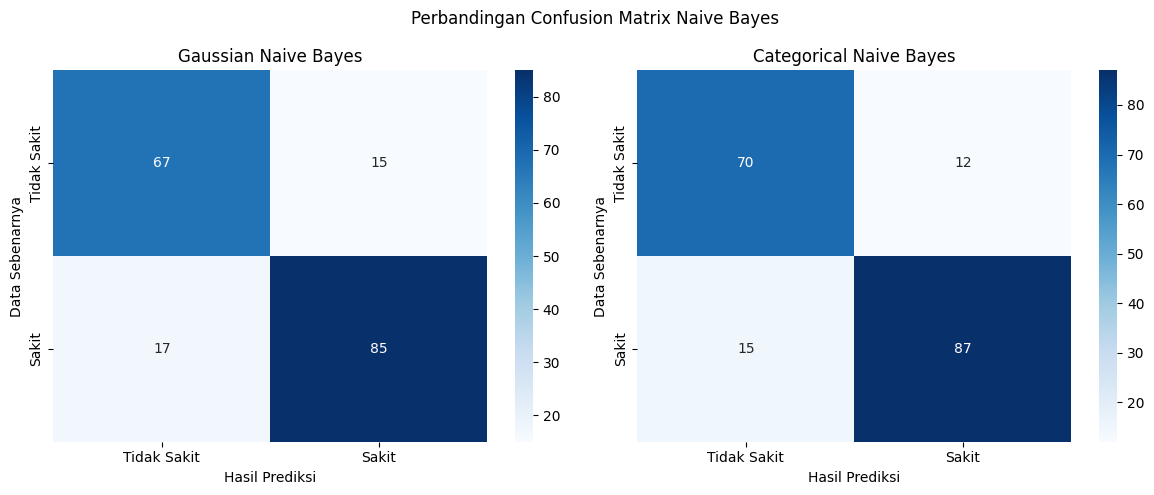

In [32]:

# ==========================================
# CONFUSION MATRIX NAIVE BAYES
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

hasil_prediksi = [
    (pred_gaussian, "Gaussian Naive Bayes"),
    (pred_categorical, "Categorical Naive Bayes")
]

for ax, (prediksi, nama) in zip(axes, hasil_prediksi):

    cm = confusion_matrix(y_test, prediksi)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Tidak Sakit", "Sakit"],
        yticklabels=["Tidak Sakit", "Sakit"],
        ax=ax
    )

    ax.set_title(nama)
    ax.set_xlabel("Hasil Prediksi")
    ax.set_ylabel("Data Sebenarnya")

plt.suptitle("Perbandingan Confusion Matrix Naive Bayes")
plt.tight_layout()
plt.show()


# Tahap 11 Membuat tabel hasil evaluasi

In [33]:

# ==========================================
# TABEL HASIL EVALUASI
# ==========================================

hasil_nb = pd.DataFrame([
    hasil_gaussian,
    hasil_categorical
])

print("TABEL PERBANDINGAN NAIVE BAYES")

display(
    hasil_nb.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1-Score": "{:.2%}"
    })
)


TABEL PERBANDINGAN NAIVE BAYES


,Algoritma,Accuracy,Precision,Recall,F1-Score
0,Gaussian Naive Bayes,82.61%,85.00%,83.33%,84.16%
1,Categorical Naive Bayes,85.33%,87.88%,85.29%,86.57%


# Tahap 12 - Visualisasi perbandingan algoritma Naive Bayes

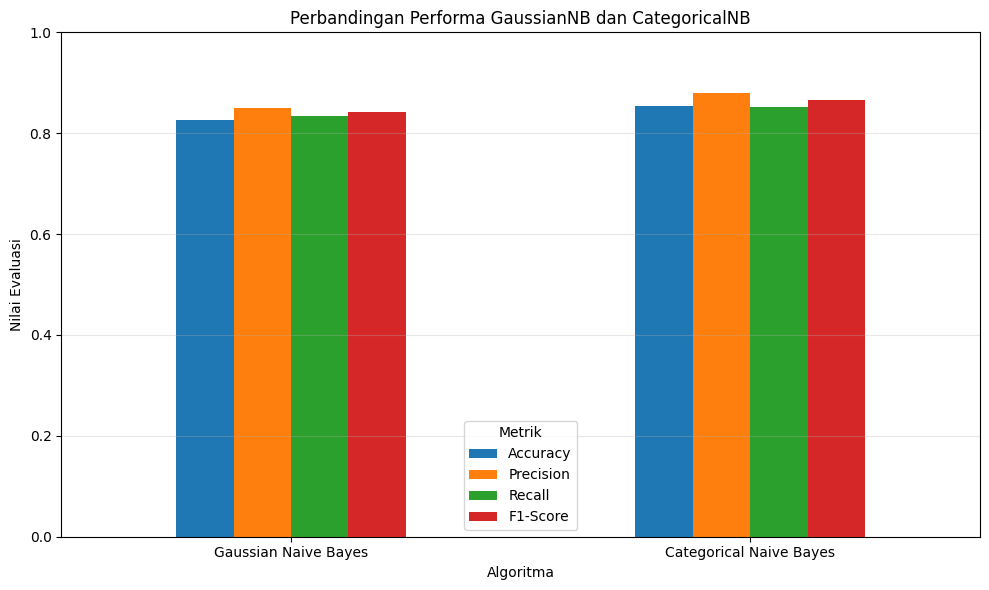

In [34]:

# ==========================================
# VISUALISASI PERBANDINGAN NAIVE BAYES
# ==========================================

metrik = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

hasil_plot = hasil_nb.set_index("Algoritma")[metrik]

hasil_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Perbandingan Performa GaussianNB dan CategoricalNB")
plt.xlabel("Algoritma")
plt.ylabel("Nilai Evaluasi")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Metrik")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# Tahap 13 - Membandingkan dengan k-NN terbaik dari Varian 2 dan Menentukan model Naive Bayes terbaik

Tahap ini digunakan untuk membandingkan algoritma Naive Bayes dengan algoritma k-NN yang memperoleh hasil terbaik pada eksperimen parameter.
Agar hasilnya bisa dibandingkan, k-NN akan dilatih kembali menggunakan pembagian data dan preprocessing yang sama dengan eksperimen sebelumnya.
Untuk perbandingan akhir, GaussianNB dan CategoricalNB pada kode di atas menggunakan kelompok fitur berbeda. Jadi, perbandingannya belum sepenuhnya setara dengan k-NN yang menggunakan seluruh fitur. Hasil ini dapat menunjukkan performa masing-masing kelompok fitur, tetapi belum membuktikan algoritma mana yang lebih baik secara adil.
Untuk perbandingan algoritma yang lebih setara, bagian ini juga perlu menggunakan model Naive Bayes yang menggabungkan informasi numerik dan kategorik atau menggunakan representasi fitur yang sama.

Model terbaik ditentukan berdasarkan nilai Accuracy dan F1-Score. Kedua metrik diperhatikan agar pemilihan model tidak hanya berdasarkan ketepatan keseluruhan.

In [35]:

# ==========================================
# MENENTUKAN MODEL NAIVE BAYES TERBAIK
# ==========================================

model_terbaik_nb = hasil_nb.sort_values(
    by=["F1-Score", "Accuracy"],
    ascending=False
).iloc[0]

print("====================================")
print("MODEL NAIVE BAYES TERBAIK")
print("====================================")

print("Algoritma :", model_terbaik_nb["Algoritma"])
print("Accuracy  :", round(model_terbaik_nb["Accuracy"], 4))
print("Precision :", round(model_terbaik_nb["Precision"], 4))
print("Recall    :", round(model_terbaik_nb["Recall"], 4))
print("F1-Score  :", round(model_terbaik_nb["F1-Score"], 4))


MODEL NAIVE BAYES TERBAIK
Algoritma : Categorical Naive Bayes
Accuracy  : 0.8533
Precision : 0.8788
Recall    : 0.8529
F1-Score  : 0.8657


# Tahap 14 - Kesimpulan hasil eksperimen

In [36]:

# ==========================================
# KESIMPULAN VARIAN 3
# ==========================================

print("KESIMPULAN EKSPERIMEN VARIAN 3")
print("------------------------------------")

print(
    f"Model terbaik adalah "
    f"{model_terbaik_nb['Algoritma']}"
)

print(
    f"Accuracy: "
    f"{model_terbaik_nb['Accuracy']:.2%}"
)

print(
    f"F1-Score: "
    f"{model_terbaik_nb['F1-Score']:.2%}"
)

print(
    "\nKedua model telah diuji menggunakan "
    "pembagian data training dan testing yang sama."
)


KESIMPULAN EKSPERIMEN VARIAN 3
------------------------------------
Model terbaik adalah Categorical Naive Bayes
Accuracy: 85.33%
F1-Score: 86.57%

Kedua model telah diuji menggunakan pembagian data training dan testing yang sama.
